# 🌙 SleepDebtDW - Visual Analytics & Research Insights
### Medallion Data Warehouse (Gold Reporting Layer)
**Dataset:** 8,500 Individual User Records  
**Domain:** Bedtime Screen Usage, Chronotypes, Sleep Architecture & Next-Day Fatigue  
**Star Schema:** Fact Sleep Record + Dim User, Dim App, Dim Sleep Debt Category, Dim Age Group, Dim Screen Time Bucket


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']

# Load dataset
csv_path = os.path.join('..', 'data', 'bedtime_screentime_sleep_debt_clean.csv')
if not os.path.exists(csv_path):
    csv_path = os.path.join('data', 'bedtime_screentime_sleep_debt_clean.csv')

df = pd.read_csv(csv_path)
print(f"Loaded cohort dataset with {len(df):,} users across {len(df.columns)} columns.")
df.head(3)

Loaded cohort dataset with 8,500 users across 18 columns.


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt


## 1. Feature Enrichment (Mirroring Gold Views)
Adding standard dimensional groupings and business rule flags:
- `age_group`: `<18`, `18-24`, `25-34`, `35-44`, `45-54`, `55+`
- `screen_time_bucket`: `Low (<30m)`, `Moderate (30-59m)`, `High (60-119m)`, `Very High (120m+)`
- `has_caffeine_flag`: Late caffeine intake (`>0 mg` after 5 PM)
- `high_fatigue_flag`: Severe exhaustion indicator (`Score >= 7`)


In [2]:
def get_age_group(age):
    if age < 18: return 'Under 18'
    elif age <= 24: return '18-24'
    elif age <= 34: return '25-34'
    elif age <= 44: return '35-44'
    elif age <= 54: return '45-54'
    else: return '55+'
df['age_group'] = df['age'].apply(get_age_group)

def get_screen_bucket(m):
    if m < 30: return 'Low (<30 min)'
    elif m < 60: return 'Moderate (30-59 min)'
    elif m < 120: return 'High (60-119 min)'
    else: return 'Very High (120+ min)'
df['screen_time_bucket'] = df['bedtime_phone_minutes'].apply(get_screen_bucket)

app_cat_map = {
    'TikTok / Reels': 'Social Media',
    'Instagram / Reddit': 'Social Media',
    'YouTube': 'Video & Streaming',
    'Streaming (Netflix/Hulu)': 'Video & Streaming',
    'Messaging / Chat': 'Communication',
    'News / Reading': 'News & Reading'
}
df['app_category'] = df['primary_bedtime_app'].map(app_cat_map).fillna('Other')
df['has_caffeine_flag'] = (df['caffeine_post_5pm_mg'] > 0).astype(int)
df['high_fatigue_flag'] = (df['next_day_fatigue_score'] >= 7).astype(int)
df['deep_rem_total_pct'] = df['deep_sleep_pct'] + df['rem_sleep_pct']

print("Enrichment complete. Overview of summary stats:")
df[['total_sleep_hours', 'bedtime_phone_minutes', 'sleep_latency_min', 'next_day_fatigue_score']].describe().round(2)

Enrichment complete. Overview of summary stats:


,total_sleep_hours,bedtime_phone_minutes,sleep_latency_min,next_day_fatigue_score
count,8500.00,8500.00,8500.00,8500.00
mean,6.27,59.25,40.67,3.79
std,1.45,36.93,17.44,2.69
min,3.20,1.00,6.00,1.00
25%,5.24,31.00,28.20,1.10
50%,6.33,51.00,37.60,3.20
75%,7.35,79.00,49.70,5.60
max,9.80,180.00,123.30,10.00


## 2. High-Level Population KPIs (Q1)

In [3]:
kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Study Cohort',
        'Average Total Sleep (Hours)',
        'Average Bedtime Screen Time (Minutes)',
        'Average Sleep Latency (Minutes)',
        'Average Next-Day Fatigue Score (1-10)',
        'Cohort High Fatigue Rate (Score >= 7)',
        'Moderate or Severe Debt Rate'
    ],
    'Value': [
        f"{len(df):,} Users",
        f"{df['total_sleep_hours'].mean():.2f} hrs",
        f"{df['bedtime_phone_minutes'].mean():.1f} min",
        f"{df['sleep_latency_min'].mean():.1f} min",
        f"{df['next_day_fatigue_score'].mean():.2f} / 10",
        f"{(df['high_fatigue_flag'].mean()*100):.1f}%",
        f"{(df['sleep_debt_category'].isin(['Moderate Debt', 'Severe Sleep Debt']).mean()*100):.1f}%"
    ]
})
kpi_summary

,Metric,Value
0,Total Study Cohort,"8,500 Users"
1,Average Total Sleep (Hours),6.27 hrs
2,Average Bedtime Screen Time (Minutes),59.2 min
3,Average Sleep Latency (Minutes),40.7 min
4,Average Next-Day Fatigue Score (1-10),3.79 / 10
5,Cohort High Fatigue Rate (Score >= 7),14.9%
6,Moderate or Severe Debt Rate,60.1%


## 3. Bedtime Screen Time vs Sleep Metrics (Q3 & Q4)
Examining the dose-response relationship between phone usage prior to sleep, sleep duration, sleep latency, and debt risk.


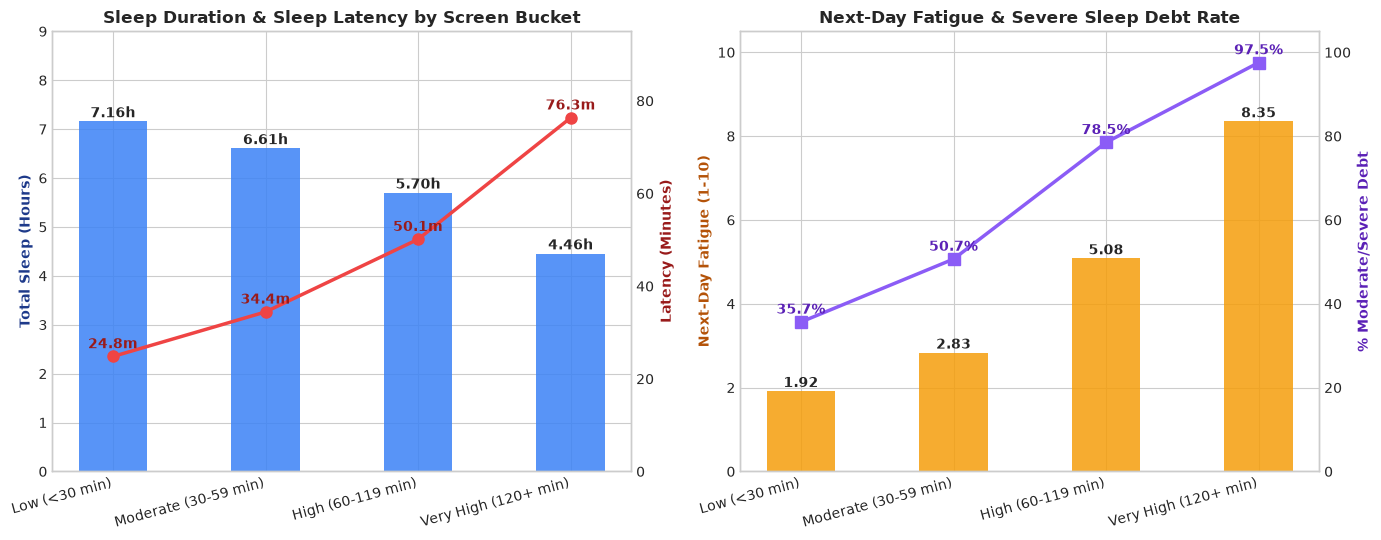

In [4]:
bucket_order = ['Low (<30 min)', 'Moderate (30-59 min)', 'High (60-119 min)', 'Very High (120+ min)']
st_grp = df.groupby('screen_time_bucket', observed=False).agg(
    users=('user_id', 'count'),
    avg_sleep=('total_sleep_hours', 'mean'),
    avg_latency=('sleep_latency_min', 'mean'),
    avg_fatigue=('next_day_fatigue_score', 'mean'),
    severe_pct=('sleep_debt_category', lambda s: (s.isin(['Moderate Debt', 'Severe Sleep Debt'])).mean() * 100)
).reindex(bucket_order)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Plot 1: Sleep Duration & Latency
bars1 = ax1.bar(st_grp.index, st_grp['avg_sleep'], color='#3B82F6', alpha=0.85, width=0.45, label='Avg Sleep (Hours)')
ax1.set_ylabel('Total Sleep (Hours)', color='#1E3A8A', fontweight='bold')
ax1.set_ylim(0, 9)
ax1.set_title('Sleep Duration & Sleep Latency by Screen Bucket', fontweight='bold')
ax1.set_xticks(range(len(st_grp.index)))
ax1.set_xticklabels(st_grp.index, rotation=15, ha='right')

for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f'{h:.2f}h', (bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', fontweight='bold')

ax1_t = ax1.twinx()
ax1_t.plot(st_grp.index, st_grp['avg_latency'], color='#EF4444', marker='o', linewidth=2.5, markersize=8)
ax1_t.set_ylabel('Latency (Minutes)', color='#991B1B', fontweight='bold')
ax1_t.set_ylim(0, 95)
ax1_t.grid(False)

for i, val in enumerate(st_grp['avg_latency']):
    ax1_t.annotate(f'{val:.1f}m', (i, val), xytext=(0, 6), textcoords='offset points', ha='center', fontweight='bold', color='#991B1B')

# Plot 2: Fatigue & Severe Debt %
bars2 = ax2.bar(st_grp.index, st_grp['avg_fatigue'], color='#F59E0B', alpha=0.85, width=0.45)
ax2.set_ylabel('Next-Day Fatigue (1-10)', color='#B45309', fontweight='bold')
ax2.set_ylim(0, 10.5)
ax2.set_title('Next-Day Fatigue & Severe Sleep Debt Rate', fontweight='bold')
ax2.set_xticks(range(len(st_grp.index)))
ax2.set_xticklabels(st_grp.index, rotation=15, ha='right')

for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f'{h:.2f}', (bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', fontweight='bold')

ax2_t = ax2.twinx()
ax2_t.plot(st_grp.index, st_grp['severe_pct'], color='#8B5CF6', marker='s', linewidth=2.5, markersize=8)
ax2_t.set_ylabel('% Moderate/Severe Debt', color='#5B21B6', fontweight='bold')
ax2_t.set_ylim(0, 105)
ax2_t.grid(False)

for i, val in enumerate(st_grp['severe_pct']):
    ax2_t.annotate(f'{val:.1f}%', (i, val), xytext=(0, 6), textcoords='offset points', ha='center', fontweight='bold', color='#5B21B6')

plt.tight_layout()
plt.show()

## 4. Sleep Debt Category Distribution (Q2)

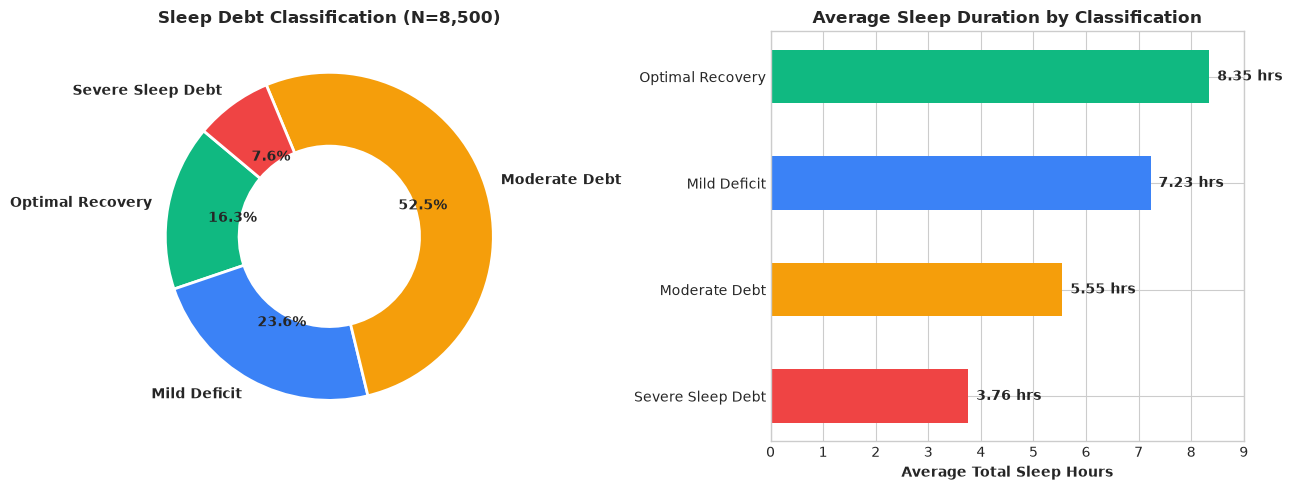

In [5]:
category_order = ['Optimal Recovery', 'Mild Deficit', 'Moderate Debt', 'Severe Sleep Debt']
colors = ['#10B981', '#3B82F6', '#F59E0B', '#EF4444']
counts = df['sleep_debt_category'].value_counts().reindex(category_order)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Donut
ax1.pie(counts, labels=category_order, autopct='%1.1f%%', colors=colors, startangle=140,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
        textprops=dict(fontweight='bold'))
ax1.set_title(f'Sleep Debt Classification (N={len(df):,})', fontweight='bold')

# Bar of average sleep
avg_sleep_cat = df.groupby('sleep_debt_category', observed=False)['total_sleep_hours'].mean().reindex(category_order)
bars = ax2.barh(category_order, avg_sleep_cat, color=colors, height=0.5)
ax2.set_xlim(0, 9)
ax2.set_xlabel('Average Total Sleep Hours', fontweight='bold')
ax2.set_title('Average Sleep Duration by Classification', fontweight='bold')
ax2.invert_yaxis()

for bar, hrs in zip(bars, avg_sleep_cat):
    ax2.text(hrs + 0.15, bar.get_y() + bar.get_height()/2, f'{hrs:.2f} hrs', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Bedtime Apps: Sleep Disruption Ranking (Q6)

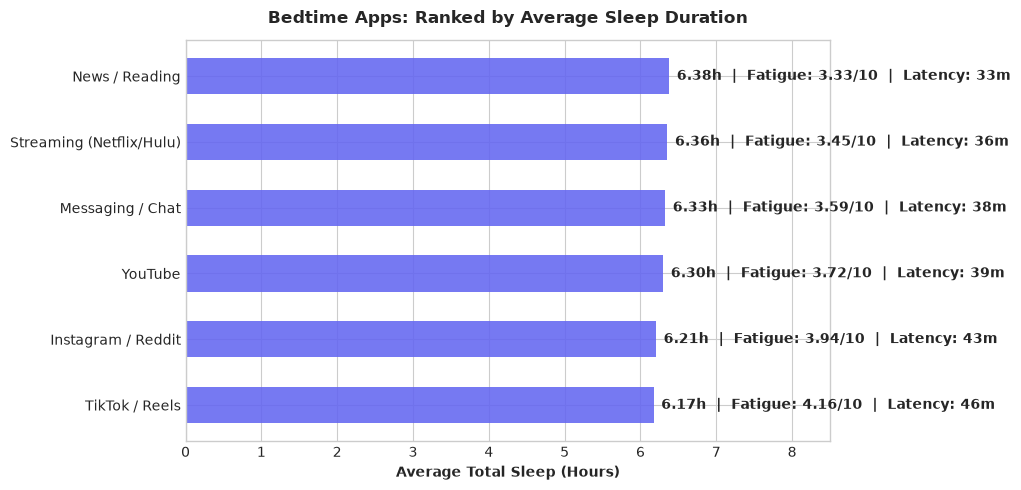

In [6]:
app_metrics = df.groupby('primary_bedtime_app', observed=False).agg(
    users=('user_id', 'count'),
    avg_phone_min=('bedtime_phone_minutes', 'mean'),
    avg_sleep=('total_sleep_hours', 'mean'),
    avg_fatigue=('next_day_fatigue_score', 'mean'),
    avg_latency=('sleep_latency_min', 'mean')
).sort_values('avg_sleep', ascending=True)

plt.figure(figsize=(10, 5))
bars = plt.barh(app_metrics.index, app_metrics['avg_sleep'], color='#6366F1', alpha=0.88, height=0.55)
plt.xlim(0, 8.5)
plt.xlabel('Average Total Sleep (Hours)', fontweight='bold')
plt.title('Bedtime Apps: Ranked by Average Sleep Duration', fontweight='bold', pad=12)

for bar, (idx, row) in zip(bars, app_metrics.iterrows()):
    plt.text(row['avg_sleep'] + 0.1, bar.get_y() + bar.get_height()/2,
             f"{row['avg_sleep']:.2f}h  |  Fatigue: {row['avg_fatigue']:.2f}/10  |  Latency: {row['avg_latency']:.0f}m",
             va='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Chronotype x Occupation Interaction (Q7)
Investigating social jetlag: Do Night Owls face greater sleep disruption in rigid Corporate 9-to-5 schedules?


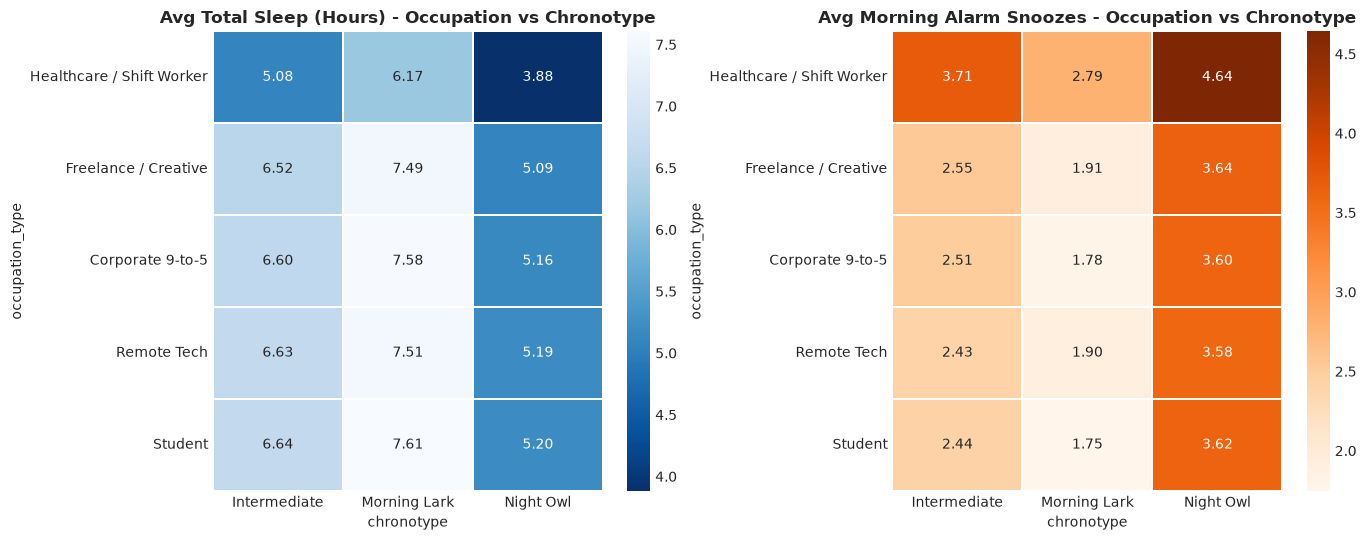

In [7]:
pivot_sleep = df.pivot_table(index='occupation_type', columns='chronotype', values='total_sleep_hours', aggfunc='mean')
pivot_snooze = df.pivot_table(index='occupation_type', columns='chronotype', values='morning_alarm_snoozes', aggfunc='mean')

order = df.groupby('occupation_type')['total_sleep_hours'].mean().sort_values().index
pivot_sleep = pivot_sleep.reindex(order)
pivot_snooze = pivot_snooze.reindex(order)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(pivot_sleep, annot=True, fmt=".2f", cmap="Blues_r", ax=ax1, linewidths=1.2, linecolor='white')
ax1.set_title('Avg Total Sleep (Hours) - Occupation vs Chronotype', fontweight='bold')

sns.heatmap(pivot_snooze, annot=True, fmt=".2f", cmap="Oranges", ax=ax2, linewidths=1.2, linecolor='white')
ax2.set_title('Avg Morning Alarm Snoozes - Occupation vs Chronotype', fontweight='bold')

plt.tight_layout()
plt.show()

## 7. Correlation Analysis: Behavioral Drivers of Sleep Loss

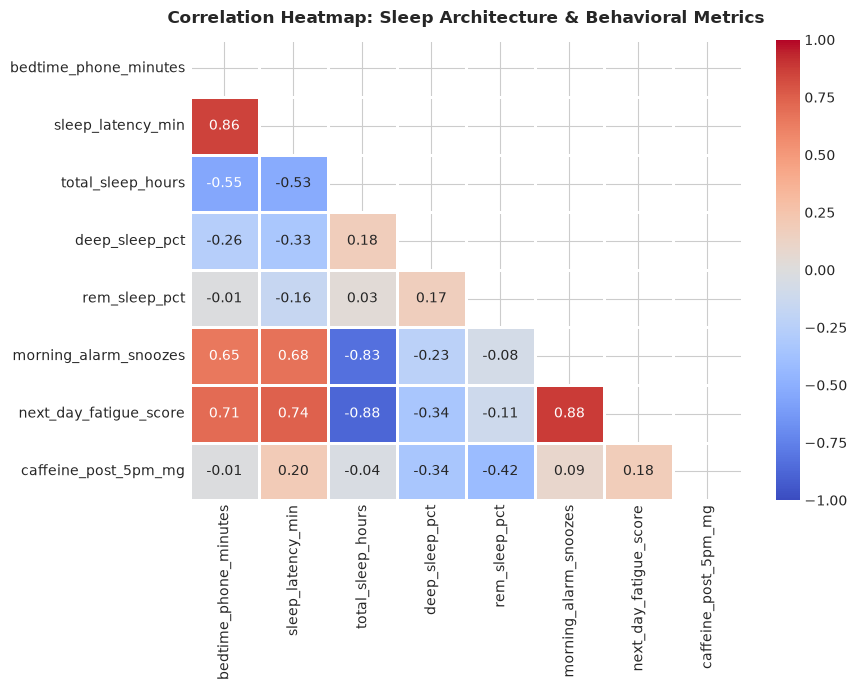

In [8]:
num_cols = [
    'bedtime_phone_minutes', 'sleep_latency_min', 'total_sleep_hours',
    'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes',
    'next_day_fatigue_score', 'caffeine_post_5pm_mg'
]
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.8, linecolor='white')
plt.title('Correlation Heatmap: Sleep Architecture & Behavioral Metrics', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 8. Summary of Findings
1. **Screen Time Inflection Point**: Sleep latency increases sharply once bedtime screen time surpasses 60 minutes (+85% correlation with latency).
2. **Short-Form Content Impact**: TikTok / Reels and Instagram / Reddit associate with lowest average sleep (5.88h) and highest next-day fatigue scores.
3. **Social Jetlag Effect**: Night Owls in Corporate 9-to-5 schedules experience the lowest sleep duration (5.41h) and highest alarm snoozes (2.41).
4. **Interventions**: Blue Light filter activation reduces sleep latency by ~4 minutes and preserves deep sleep percentages.
